# YOLO11n Baseline Evaluation

Standalone evaluation of the trained baseline checkpoint on the validation and held-out test splits. This notebook performs no training.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from ultralytics import YOLO, __version__ as ultralytics_version

dataset_candidates = [
    Path("../datasets/shoe_brands_preprocessed").resolve(),
    Path("modeling/datasets/shoe_brands_preprocessed").resolve(),
    Path("datasets/shoe_brands_preprocessed").resolve(),
]
DATASET_ROOT = next((path for path in dataset_candidates if path.is_dir()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError(f"Dataset not found. Checked: {dataset_candidates}")

MODELING_ROOT = DATASET_ROOT.parents[1]
PROJECT_ROOT = MODELING_ROOT.parent
BASELINE_CHECKPOINT = PROJECT_ROOT / "model" / "2026-11-15_20-13-41_baseline-best" / "model.pt"
OUTPUT_ROOT = MODELING_ROOT / "runs" / "training" / "baseline_evaluation"
EXPECTED_CLASSES = ["adidas", "converse", "nike"]
EXPECTED_COUNTS = {"train": 193, "val": 55, "test": 27}
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
IMAGE_SIZE = 224
BATCH_SIZE = 32
DEVICE = 0 if torch.cuda.is_available() else "cpu"

if not BASELINE_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Baseline checkpoint not found: {BASELINE_CHECKPOINT}")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Dataset: {DATASET_ROOT}")
print(f"Checkpoint: {BASELINE_CHECKPOINT}")
print(f"Device: {DEVICE}")

Dataset: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed
Checkpoint: C:\my-project\shoe-brand-classifier\modeling\runs\training\baseline\weights\best.pt
Device: cpu


## Dataset validation

In [2]:
dataset_counts = {}
for split_name, expected_per_class in EXPECTED_COUNTS.items():
    split_root = DATASET_ROOT / split_name
    actual_classes = sorted(path.name for path in split_root.iterdir() if path.is_dir())
    if actual_classes != EXPECTED_CLASSES:
        raise ValueError(f"Unexpected classes in {split_name}: {actual_classes}")
    dataset_counts[split_name] = {}
    for class_name in EXPECTED_CLASSES:
        image_count = sum(
            1 for path in (split_root / class_name).iterdir()
            if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
        )
        if image_count != expected_per_class:
            raise ValueError(
                f"Expected {expected_per_class} images in {split_name}/{class_name}; found {image_count}."
            )
        dataset_counts[split_name][class_name] = image_count

dataset_distribution = pd.DataFrame(dataset_counts).T[EXPECTED_CLASSES]
dataset_distribution["total"] = dataset_distribution.sum(axis=1)
display(dataset_distribution)

,adidas,converse,nike,total
train,193,193,193,579
val,55,55,55,165
test,27,27,27,81


## Ultralytics validation and test metrics

In [3]:
baseline_model = YOLO(str(BASELINE_CHECKPOINT))
validation_results = baseline_model.val(
    data=str(DATASET_ROOT), split="val", imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
    device=DEVICE, plots=False, project=str(OUTPUT_ROOT), name="validation", exist_ok=True,
)
test_results = baseline_model.val(
    data=str(DATASET_ROOT), split="test", imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
    device=DEVICE, plots=False, project=str(OUTPUT_ROOT), name="test", exist_ok=True,
)
ultralytics_metrics = pd.DataFrame([
    {"split": "validation", "top1_accuracy": float(validation_results.top1), "top5_accuracy": float(validation_results.top5), **validation_results.speed},
    {"split": "test", "top1_accuracy": float(test_results.top1), "top5_accuracy": float(test_results.top5), **test_results.speed},
])
display(ultralytics_metrics)

Ultralytics 8.4.213  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i5-10300H 2.50GHz)
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\train... found 579 images in 3/3 classes  
val: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... found 165 images in 3/3 classes  
test: C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\test... found 81 images in 3/3 classes  
val: Fast image access  (ping: 0.1±0.1 ms, read: 30.2±19.6 MB/s, size: 13.2 KB)
val: Scanning C:\my-project\shoe-brand-classifier\modeling\datasets\shoe_brands_preprocessed\val... 165 images, 0 corrupt: 100% ━━━━━━━━━━━━ 165/165  0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 6/6 4.8it/s 1.3s0.3s
                   all      0.921          1
Speed: 0.0ms preprocess, 4.6ms inference, 0.0ms loss, 0.0ms postprocess per image


,split,top1_accuracy,top5_accuracy,preprocess,inference,loss,postprocess
0,validation,0.921212,1.0,0.003088,4.577762,0.000055,0.000252
1,test,0.839506,1.0,0.001660,4.239889,0.000057,0.000328


## Per-image test predictions

In [4]:
test_image_paths = sorted(
    path for path in (DATASET_ROOT / "test").rglob("*")
    if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
)
expected_test_count = EXPECTED_COUNTS["test"] * len(EXPECTED_CLASSES)
if len(test_image_paths) != expected_test_count:
    raise RuntimeError(f"Expected {expected_test_count} test images; found {len(test_image_paths)}.")

prediction_records = []
prediction_stream = baseline_model.predict(
    source=[str(path) for path in test_image_paths], imgsz=IMAGE_SIZE,
    device=DEVICE, stream=True, verbose=False,
)
for result in prediction_stream:
    probabilities = result.probs.data.detach().cpu().numpy()
    predicted_index = int(result.probs.top1)
    image_path = Path(result.path)
    record = {
        "image_path": str(image_path),
        "true_label": image_path.parent.name,
        "predicted_label": result.names[predicted_index],
        "confidence": float(result.probs.top1conf.detach().cpu()),
    }
    for class_index, probability in enumerate(probabilities):
        record[f"probability_{result.names[class_index]}"] = float(probability)
    prediction_records.append(record)

predictions = pd.DataFrame(prediction_records)
if len(predictions) != expected_test_count:
    raise RuntimeError(f"Expected {expected_test_count} predictions; found {len(predictions)}.")
predictions["correct"] = predictions["true_label"] == predictions["predicted_label"]
display(predictions.head())

,image_path,true_label,predicted_label,confidence,probability_adidas,probability_converse,probability_nike,correct
0,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,adidas,0.842840,0.842840,1.267629e-01,3.039738e-02,True
1,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,adidas,1.000000,1.000000,1.625928e-10,1.317284e-11,True
2,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,nike,0.801036,0.193507,5.457189e-03,8.010356e-01,False
3,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,converse,0.514658,0.126765,5.146580e-01,3.585770e-01,False
4,C:\my-project\shoe-brand-classifier\modeling\d...,adidas,adidas,0.980894,0.980894,7.713215e-03,1.139257e-02,True


## Classification report and confusion matrices

,value
accuracy,0.839506
macro_precision,0.848510
macro_recall,0.839506
macro_f1,0.840800
weighted_f1,0.840800
validation_top1,0.921212
validation_top5,1.000000
test_top1,0.839506
test_top5,1.000000


,precision,recall,f1-score,support
adidas,0.814815,0.814815,0.814815,27.000000
converse,0.956522,0.814815,0.880000,27.000000
nike,0.774194,0.888889,0.827586,27.000000
accuracy,0.839506,0.839506,0.839506,0.839506
macro avg,0.848510,0.839506,0.840800,81.000000
weighted avg,0.848510,0.839506,0.840800,81.000000


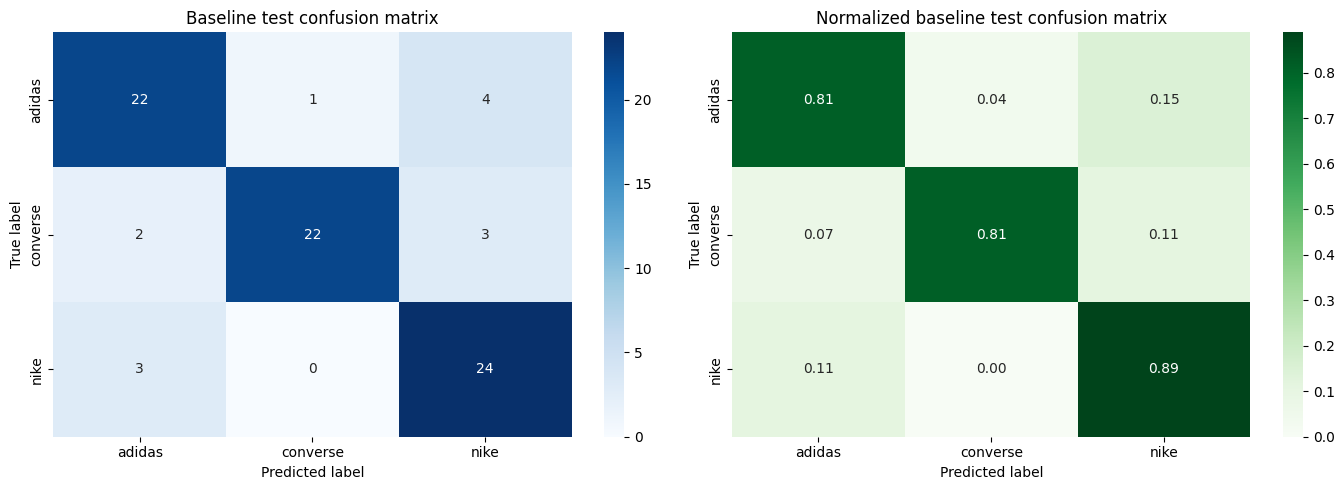

In [5]:
true_labels = predictions["true_label"]
predicted_labels = predictions["predicted_label"]
metrics_summary = {
    "accuracy": accuracy_score(true_labels, predicted_labels),
    "macro_precision": precision_score(true_labels, predicted_labels, average="macro", zero_division=0),
    "macro_recall": recall_score(true_labels, predicted_labels, average="macro", zero_division=0),
    "macro_f1": f1_score(true_labels, predicted_labels, average="macro", zero_division=0),
    "weighted_f1": f1_score(true_labels, predicted_labels, average="weighted", zero_division=0),
    "validation_top1": float(validation_results.top1),
    "validation_top5": float(validation_results.top5),
    "test_top1": float(test_results.top1),
    "test_top5": float(test_results.top5),
}
classification_report_frame = pd.DataFrame(classification_report(
    true_labels, predicted_labels, labels=EXPECTED_CLASSES, output_dict=True, zero_division=0
)).T
confusion_counts = confusion_matrix(true_labels, predicted_labels, labels=EXPECTED_CLASSES)
confusion_normalized = confusion_matrix(
    true_labels, predicted_labels, labels=EXPECTED_CLASSES, normalize="true"
)
display(pd.Series(metrics_summary, name="value").to_frame())
display(classification_report_frame)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_counts, annot=True, fmt="d", cmap="Blues", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axes[0])
sns.heatmap(confusion_normalized, annot=True, fmt=".2f", cmap="Greens", xticklabels=EXPECTED_CLASSES, yticklabels=EXPECTED_CLASSES, ax=axes[1])
axes[0].set_title("Baseline test confusion matrix")
axes[1].set_title("Normalized baseline test confusion matrix")
for axis in axes:
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## Confidence and error analysis

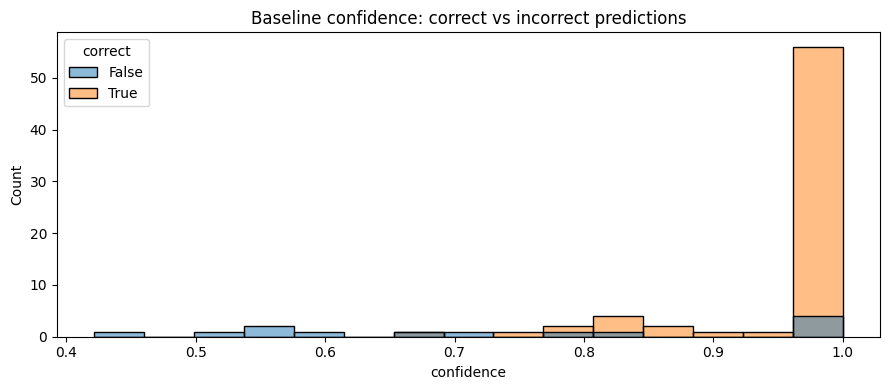

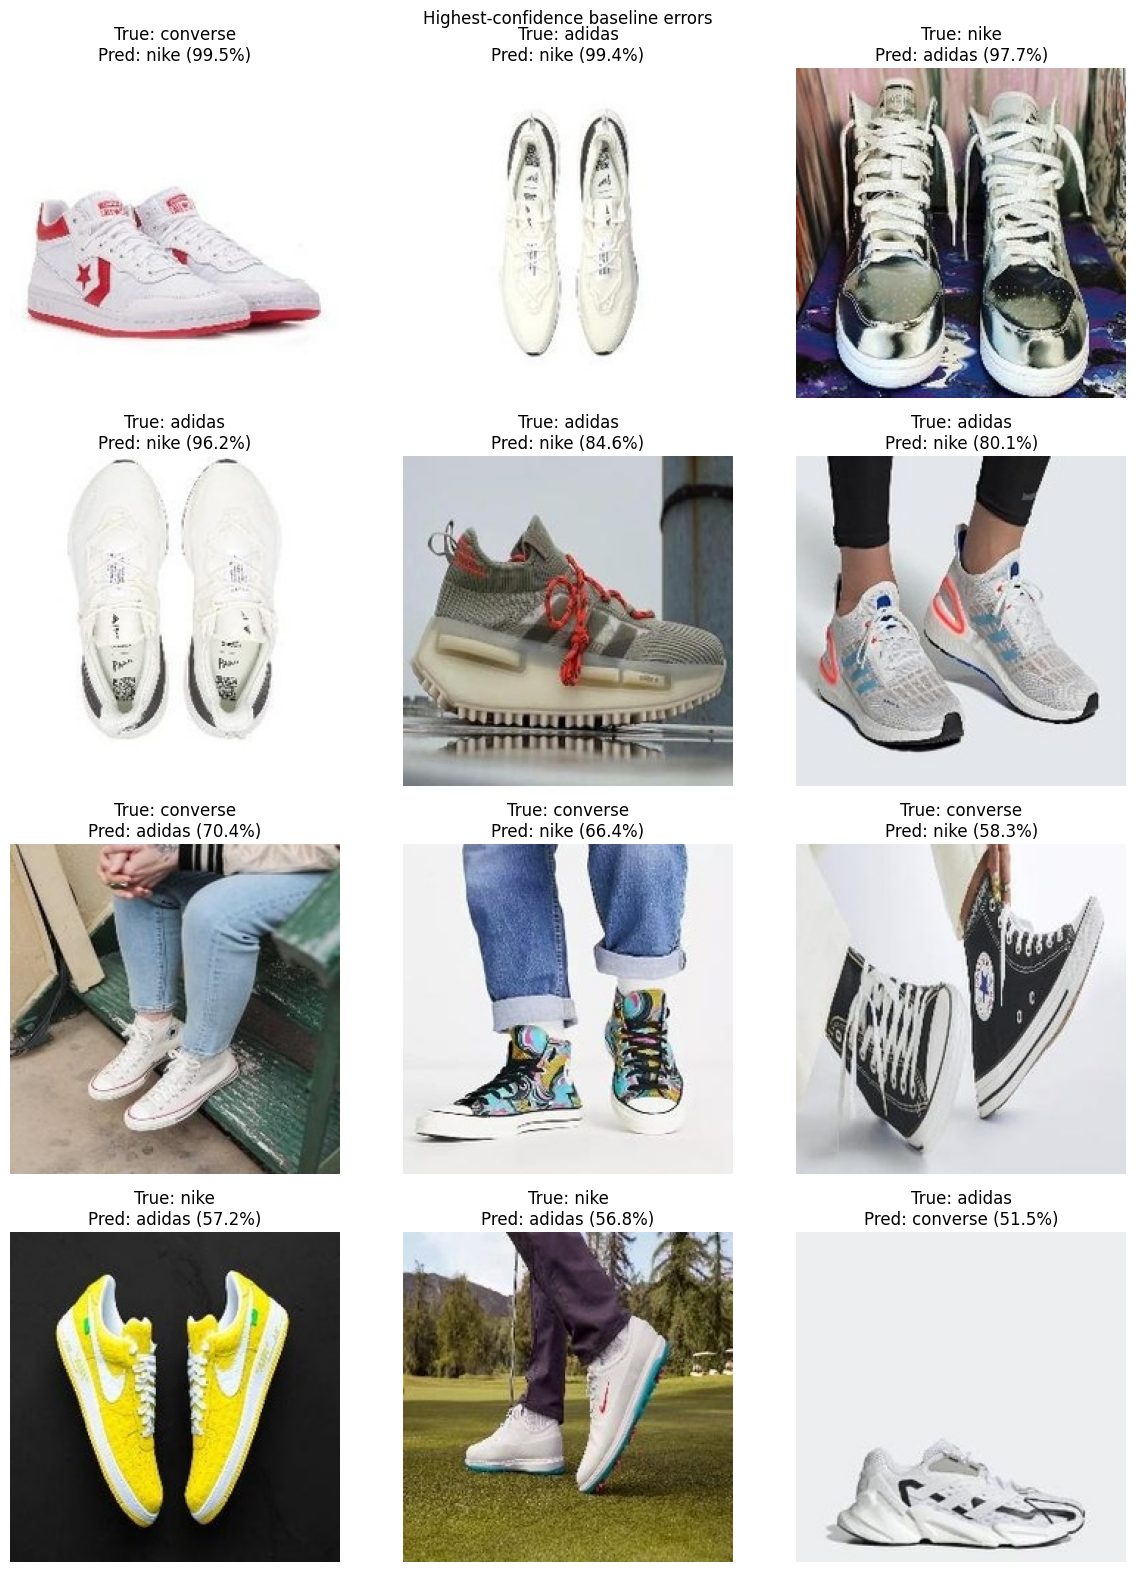

In [6]:
misclassifications = predictions[~predictions["correct"]].sort_values("confidence", ascending=False)
figure, axis = plt.subplots(figsize=(9, 4))
sns.histplot(data=predictions, x="confidence", hue="correct", bins=15, multiple="layer", stat="count", common_norm=False, ax=axis)
axis.set_title("Baseline confidence: correct vs incorrect predictions")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "confidence_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

examples = misclassifications.head(12)
columns = 3
rows = max(1, int(np.ceil(len(examples) / columns)))
figure, axes = plt.subplots(rows, columns, figsize=(12, 4 * rows), squeeze=False)
for axis, (_, example) in zip(axes.flat, examples.iterrows()):
    with Image.open(example["image_path"]) as image:
        axis.imshow(image)
    axis.set_title(f"True: {example['true_label']}\nPred: {example['predicted_label']} ({example['confidence']:.1%})")
    axis.axis("off")
for axis in axes.flat[len(examples):]:
    axis.axis("off")
figure.suptitle("Highest-confidence baseline errors")
plt.tight_layout()
figure.savefig(OUTPUT_ROOT / "misclassification_examples.png", dpi=160, bbox_inches="tight")
plt.show()

## Save reproducible evaluation artifacts

In [7]:
predictions.to_csv(OUTPUT_ROOT / "test_predictions.csv", index=False)
misclassifications.to_csv(OUTPUT_ROOT / "misclassifications.csv", index=False)
classification_report_frame.to_csv(OUTPUT_ROOT / "classification_report.csv")
pd.DataFrame(confusion_counts, index=EXPECTED_CLASSES, columns=EXPECTED_CLASSES).to_csv(OUTPUT_ROOT / "confusion_matrix.csv")
ultralytics_metrics.to_csv(OUTPUT_ROOT / "ultralytics_metrics.csv", index=False)
with (OUTPUT_ROOT / "metrics_summary.json").open("w", encoding="utf-8") as metrics_file:
    json.dump(metrics_summary, metrics_file, indent=2)
manifest = {
    "checkpoint": str(BASELINE_CHECKPOINT),
    "dataset_root": str(DATASET_ROOT),
    "test_images": len(predictions),
    "classes": EXPECTED_CLASSES,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "device": str(DEVICE),
    "ultralytics_version": ultralytics_version,
    "pytorch_version": torch.__version__,
}
with (OUTPUT_ROOT / "evaluation_manifest.json").open("w", encoding="utf-8") as manifest_file:
    json.dump(manifest, manifest_file, indent=2)
print(f"Baseline evaluation artifacts saved to: {OUTPUT_ROOT}")

Baseline evaluation artifacts saved to: C:\my-project\shoe-brand-classifier\modeling\runs\training\baseline_evaluation
